# ==============================================================================
# BÀI TẬP 3: ỔN ĐỊNH HUẤN LUYỆN NÂNG CAO VỚI WASSERSTEIN GAN - GRADIENT PENALTY (WGAN-GP)
# ==============================================================================

### 🎯 Mục tiêu bài học:
1. **Bản chất toán học của khoảng cách Wasserstein-1 (Earth Mover's Distance):**
   * Khắc phục nhược điểm cốt tử của phân kỳ Jensen-Shannon (JS Divergence) trong Vanilla GAN khi hai phân phối không giao thoa nhau trong không gian số chiều cao.
2. **Xây dựng mạng Critic thay cho Discriminator:**
   * Loại bỏ hoàn toàn hàm Sigmoid ở tầng cuối cùng để xuất ra điểm số thực unconstrained (Wasserstein score).
   * **Quy tắc thiết kế:** Không dùng Batch Normalization trong Critic nhằm bảo toàn tính độc lập của từng mẫu khi tính gradient penalty.
3. **Cài đặt chuẩn xác hàm mất mát WGAN-GP:**
   $$\mathcal{L}_{Critic} = \mathbb{E}_{\tilde{x}}[D(\tilde{x})] - \mathbb{E}_x[D(x)] + \lambda \mathbb{E}_{\hat{x}}\left[(\|\nabla_{\hat{x}} D(\hat{x})\|_2 - 1)^2\right]$$
   * Lấy mẫu nội suy tuyến tính: $\hat{x} = \epsilon x + (1 - \epsilon)\tilde{x}$ với $\epsilon \sim U(0, 1)$.
   * Sử dụng `torch.autograd.grad` để tính gradient vi phân và ràng buộc Lipschitz với hệ số $\lambda = 10$.
4. **Chiến lược tối ưu hóa:** Huấn luyện Critic $n_{critic} = 5$ bước cho mỗi 1 bước cập nhật của Generator.
5. **Báo cáo định lượng:** Minh chứng tại sao Critic Loss phản ánh trực tiếp chất lượng ảnh sinh ra.

In [1]:
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

# Cố định seed
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[+] Thiết bị thực thi: {device}")

[+] Thiết bị thực thi: cuda


In [2]:
# ==============================================================================
# 1. CHUẨN BỊ TẬP DỮ LIỆU FASHION-MNIST
# ==============================================================================
transform = transforms.Compose([
    transforms.Resize(32), # Resize 32x32 để kiến trúc Convolutional đối xứng, thuận tiện
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)) # [-1, 1]
])

train_dataset = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, drop_last=True)

print(f"[+] Số lượng ảnh: {len(train_dataset):,} mẫu (32x32x1)")

  0%|          | 0.00/26.4M [00:00<?, ?B/s]

  0%|          | 32.8k/26.4M [00:00<02:45, 159kB/s]

  0%|          | 65.5k/26.4M [00:00<02:45, 159kB/s]

  0%|          | 98.3k/26.4M [00:00<02:44, 160kB/s]

  1%|          | 229k/26.4M [00:00<01:16, 344kB/s] 

...

 90%|█████████ | 4.00M/4.42M [00:01<00:00, 3.68MB/s]

100%|██████████| 4.42M/4.42M [00:01<00:00, 2.29MB/s]

  0%|          | 0.00/5.15k [00:00<?, ?B/s]

100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]

[+] Số lượng ảnh: 60,000 mẫu (32x32x1)


In [3]:
# ==============================================================================
# 2. XÂY DỰNG GENERATOR VÀ CRITIC (KHÔNG DÙNG SIGMOID & BATCHNORM TRONG CRITIC)
# ==============================================================================

class WGAN_Generator(nn.Module):
    """
    Generator: z in R^100 -> Fractionally-strided Convs + BatchNorm2d + ReLU -> Tanh in [-1, 1]
    """
    def __init__(self, z_dim=100, ngf=64, channels=1):
        super().__init__()
        self.net = nn.Sequential(
            # Input: (z_dim) x 1 x 1 -> (ngf*4) x 4 x 4
            nn.ConvTranspose2d(z_dim, ngf * 4, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            
            # (ngf*4) x 4 x 4 -> (ngf*2) x 8 x 8
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            
            # (ngf*2) x 8 x 8 -> ngf x 16 x 16
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            
            # ngf x 16 x 16 -> channels x 32 x 32
            nn.ConvTranspose2d(ngf, channels, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z)


class WGAN_Critic(nn.Module):
    """
    Critic (WGAN-GP):
    - Không dùng Sigmoid ở đầu ra (cho điểm số Wasserstein thực).
    - Không dùng BatchNorm (thay bằng InstanceNorm2d hoặc LeakyReLU thuần)
      vì BatchNorm tạo phụ thuộc chéo giữa các mẫu trong batch, làm vi phạm định lý 1-Lipschitz.
    """
    def __init__(self, channels=1, ndf=64):
        super().__init__()
        self.net = nn.Sequential(
            # 32x32 -> 16x16
            nn.Conv2d(channels, ndf, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),
            
            # 16x16 -> 8x8
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1),
            nn.InstanceNorm2d(ndf * 2, affine=True),
            nn.LeakyReLU(0.2, inplace=True),
            
            # 8x8 -> 4x4
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1),
            nn.InstanceNorm2d(ndf * 4, affine=True),
            nn.LeakyReLU(0.2, inplace=True),
            
            # 4x4 -> 1x1 scalar
            nn.Conv2d(ndf * 4, 1, 4, 1, 0)
        )

    def forward(self, x):
        return self.net(x).view(-1, 1)

z_dim = 100
netG = WGAN_Generator(z_dim=z_dim, ngf=64, channels=1).to(device)
netC = WGAN_Critic(channels=1, ndf=64).to(device)

# Khởi tạo trọng số N(0, 0.02)
def weights_init(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight.data, 0.0, 0.02)

netG.apply(weights_init)
netC.apply(weights_init)

# Optimizer Adam theo chuẩn bài báo WGAN-GP: lr=1e-4, beta1=0.0, beta2=0.9
optG = torch.optim.Adam(netG.parameters(), lr=1e-4, betas=(0.0, 0.9))
optC = torch.optim.Adam(netC.parameters(), lr=1e-4, betas=(0.0, 0.9))

fixed_noise = torch.randn(64, z_dim, 1, 1, device=device)
print("[+] Đã hoàn thành khởi tạo WGAN-GP Generator và Critic!")

[+] Đã hoàn thành khởi tạo WGAN-GP Generator và Critic!


In [4]:
# ==============================================================================
# 3. CÀI ĐẶT TOÁN TỬ GRADIENT PENALTY VỚI TORCH.AUTOGRAD.GRAD
# Ràng buộc chuẩn Gradient sát mức 1: (||grad||_2 - 1)^2 với lambda = 10
# ==============================================================================

def compute_gradient_penalty(critic, real_samples, fake_samples, lambda_gp=10.0):
    """
    Tính hình phạt gradient penalty (1-Lipschitz constraint):
    x_hat = epsilon * x_real + (1 - epsilon) * x_fake
    GP = lambda * E[(||grad_{x_hat} D(x_hat)||_2 - 1)^2]
    """
    batch_size = real_samples.size(0)
    # Lấy mẫu epsilon ngẫu nhiên đều U(0, 1)
    epsilon = torch.rand(batch_size, 1, 1, 1, device=device)
    
    # Nội suy tuyến tính giữa ảnh thật và ảnh giả
    interpolates = (epsilon * real_samples + (1.0 - epsilon) * fake_samples).requires_grad_(True)
    
    # Đưa ảnh nội suy qua Critic
    d_interpolates = critic(interpolates)
    
    # Vector hướng gradient của output
    fake_grad_output = torch.ones(d_interpolates.shape, device=device, requires_grad=False)
    
    # Tính gradient đạo hàm riêng của Critic theo các pixel ảnh nội suy
    gradients = torch.autograd.grad(
        outputs=d_interpolates,
        inputs=interpolates,
        grad_outputs=fake_grad_output,
        create_graph=True,
        retain_graph=True,
        only_inputs=True
    )[0]
    
    # San phẳng gradient và tính chuẩn L2 cho mỗi mẫu trong batch
    gradients = gradients.view(batch_size, -1)
    gradient_norm = gradients.norm(2, dim=1)
    
    # Hình phạt độ chệch khỏi 1
    gradient_penalty = lambda_gp * ((gradient_norm - 1.0) ** 2).mean()
    return gradient_penalty

print("[+] Đã cài đặt toán tử Gradient Penalty thành công!")

[+] Đã cài đặt toán tử Gradient Penalty thành công!


In [5]:
# ==============================================================================
# 4. VÒNG LẶP HUẤN LUYỆN WGAN-GP (n_critic = 5 BƯỚC CHO MỖI BƯỚC G)
# ==============================================================================
EPOCHS = 25
N_CRITIC = 5
LAMBDA_GP = 10.0

critic_losses = []
wasserstein_distances = []
generator_losses = []
saved_samples = {}

print("=" * 70)
print("BẮT ĐẦU HUẤN LUYỆN WGAN-GP TRONG 25 EPOCHS (n_critic = 5)")
print("=" * 70)

data_iter = iter(train_loader)
batches_per_epoch = len(train_loader)

for epoch in range(1, EPOCHS + 1):
    netC.train()
    netG.train()
    epoch_c_loss = 0.0
    epoch_w_dist = 0.0
    epoch_g_loss = 0.0
    g_steps = 0

    for step, (real_imgs, _) in enumerate(train_loader):
        b_size = real_imgs.size(0)
        real_imgs = real_imgs.to(device)

        # ----------------------------------------------------------------------
        # (1) HUẤN LUYỆN CRITIC: Tối đa hóa E[D(x)] - E[D(G(z))] - GP
        #     <==> Tối thiểu hóa E[D(G(z))] - E[D(x)] + GP
        # ----------------------------------------------------------------------
        optC.zero_grad()
        
        noise = torch.randn(b_size, z_dim, 1, 1, device=device)
        fake_imgs = netG(noise)
        
        # Điểm Critic cho ảnh thật và ảnh giả
        c_real = netC(real_imgs)
        c_fake = netC(fake_imgs.detach())
        
        # Gradient Penalty
        gp = compute_gradient_penalty(netC, real_imgs.data, fake_imgs.data, lambda_gp=LAMBDA_GP)
        
        # Khoảng cách Wasserstein ước lượng: E[D(x)] - E[D(G(z))]
        w_dist = c_real.mean() - c_fake.mean()
        
        # Loss của Critic
        loss_C = -w_dist + gp
        loss_C.backward()
        optC.step()
        
        epoch_c_loss += loss_C.item()
        epoch_w_dist += w_dist.item()

        # ----------------------------------------------------------------------
        # (2) HUẤN LUYỆN GENERATOR: Chỉ cập nhật sau mỗi n_critic = 5 bước Critic
        #     Mục tiêu: Tối đa hóa E[D(G(z))] <==> Tối thiểu hóa -E[D(G(z))]
        # ----------------------------------------------------------------------
        if (step + 1) % N_CRITIC == 0:
            optG.zero_grad()
            gen_noise = torch.randn(b_size, z_dim, 1, 1, device=device)
            gen_fake = netG(gen_noise)
            loss_G = -torch.mean(netC(gen_fake))
            loss_G.backward()
            optG.step()
            
            epoch_g_loss += loss_G.item()
            g_steps += 1

    avg_c_loss = epoch_c_loss / len(train_loader)
    avg_w_dist = epoch_w_dist / len(train_loader)
    avg_g_loss = epoch_g_loss / max(g_steps, 1)
    
    critic_losses.append(avg_c_loss)
    wasserstein_distances.append(avg_w_dist)
    generator_losses.append(avg_g_loss)
    
    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | Critic Loss: {avg_c_loss:8.4f} | "
          f"Wasserstein Dist: {avg_w_dist:8.4f} | Gen Loss: {avg_g_loss:8.4f}")

    # Lưu ảnh sinh ra tại epoch 1, 10, 25 theo đúng yêu cầu đề bài
    if epoch in [1, 10, 25]:
        netG.eval()
        with torch.no_grad():
            samples = netG(fixed_noise).cpu()
            samples = (samples + 1.0) / 2.0
            saved_samples[epoch] = samples

print("[+] Hoàn tất huấn luyện WGAN-GP!")

BẮT ĐẦU HUẤN LUYỆN WGAN-GP TRONG 25 EPOCHS (n_critic = 5)


Epoch [01/25] | Critic Loss: -12.4704 | Wasserstein Dist:  15.2483 | Gen Loss:  20.9021


Epoch [02/25] | Critic Loss:  -7.6077 | Wasserstein Dist:   8.9267 | Gen Loss:  24.5317


Epoch [03/25] | Critic Loss:  -6.6756 | Wasserstein Dist:   7.8371 | Gen Loss:  26.8899


Epoch [04/25] | Critic Loss:  -5.7291 | Wasserstein Dist:   6.6716 | Gen Loss:  27.5847


...

Epoch [21/25] | Critic Loss:  -2.7074 | Wasserstein Dist:   3.0913 | Gen Loss:  32.5502


Epoch [22/25] | Critic Loss:  -2.6881 | Wasserstein Dist:   3.0659 | Gen Loss:  32.8800


Epoch [23/25] | Critic Loss:  -2.6325 | Wasserstein Dist:   3.0082 | Gen Loss:  33.2218


Epoch [24/25] | Critic Loss:  -2.5869 | Wasserstein Dist:   2.9510 | Gen Loss:  33.4350


Epoch [25/25] | Critic Loss:  -2.5692 | Wasserstein Dist:   2.9297 | Gen Loss:  33.8418
[+] Hoàn tất huấn luyện WGAN-GP!


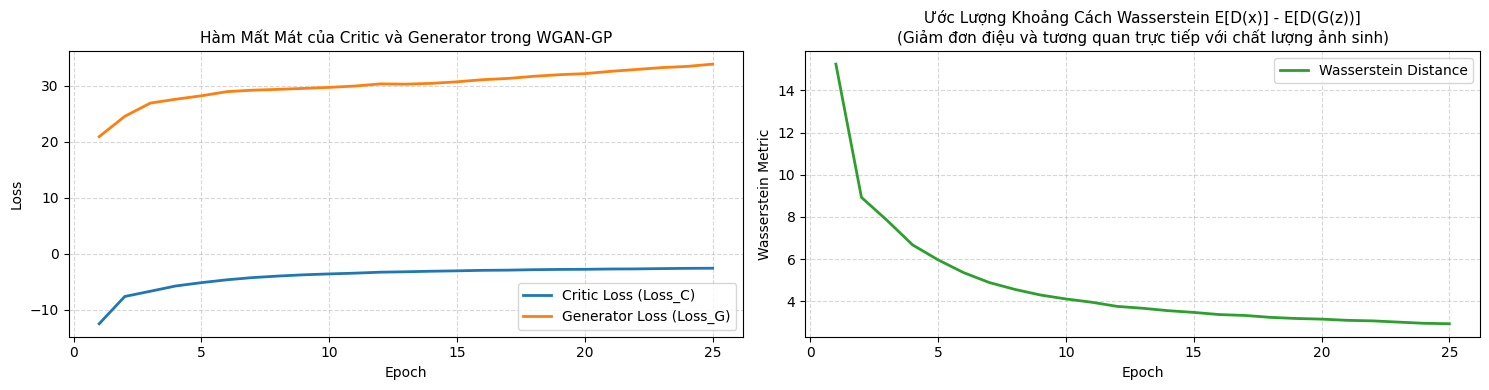

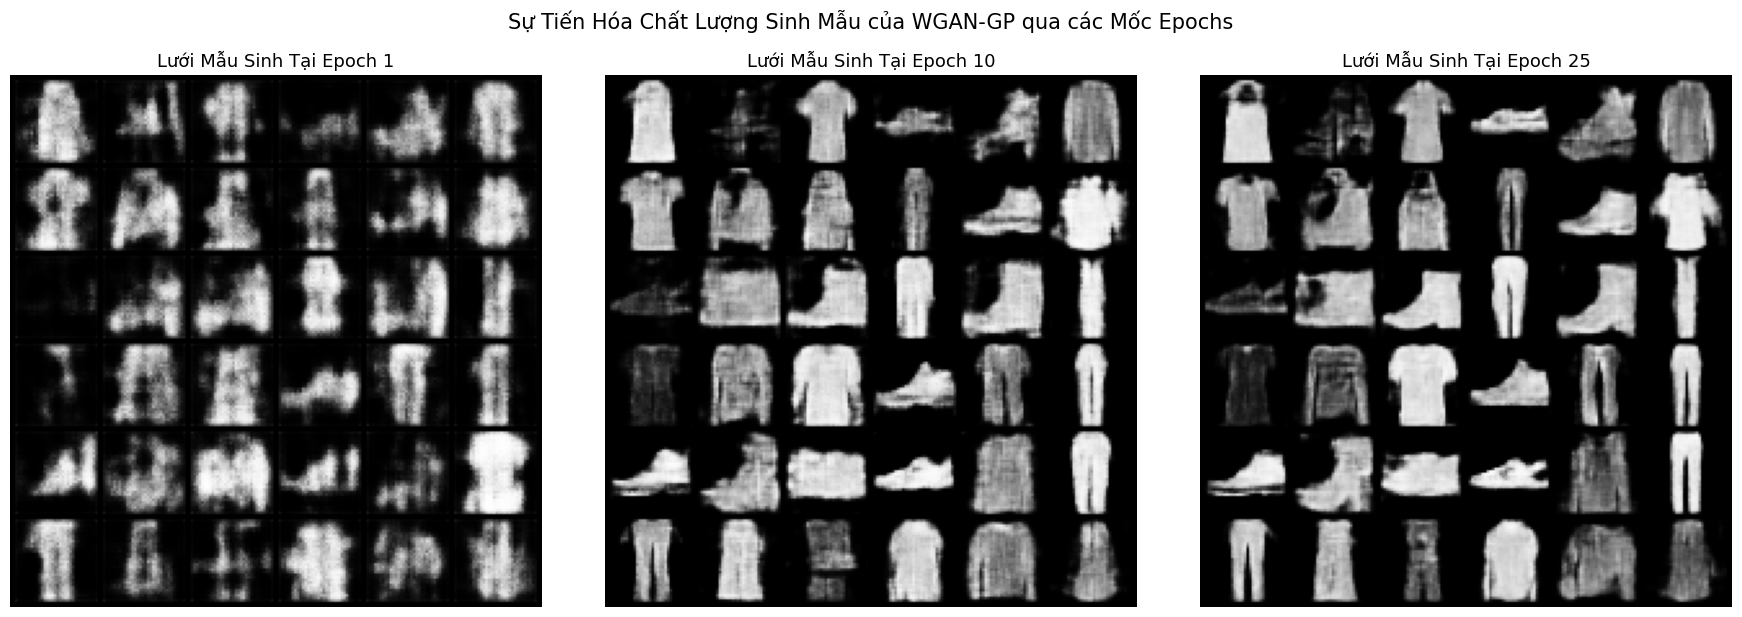

In [6]:
# ==============================================================================
# 5. TRỰC QUAN HÓA: ĐỒ THỊ LOSS & LƯỚI ẢNH TẠI EPOCH 1, 10, 25
# ==============================================================================

# 1. Đồ thị hàm mất mát Critic và Wasserstein Distance
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

axes[0].plot(range(1, EPOCHS + 1), critic_losses, color="tab:blue", lw=2, label="Critic Loss (Loss_C)")
axes[0].plot(range(1, EPOCHS + 1), generator_losses, color="tab:orange", lw=2, label="Generator Loss (Loss_G)")
axes[0].set_title("Hàm Mất Mát của Critic và Generator trong WGAN-GP", fontsize=11)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(range(1, EPOCHS + 1), wasserstein_distances, color="tab:green", lw=2, label="Wasserstein Distance")
axes[1].set_title("Ước Lượng Khoảng Cách Wasserstein E[D(x)] - E[D(G(z))]\n(Giảm đơn điệu và tương quan trực tiếp với chất lượng ảnh sinh)", fontsize=11)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Wasserstein Metric")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# 2. Lưới ảnh sinh ra tại Epoch 1, 10, 25
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
check_epochs = [1, 10, 25]

for idx, ep in enumerate(check_epochs):
    grid = make_grid(saved_samples[ep][:36], nrow=6, padding=2)
    axes[idx].imshow(grid.permute(1, 2, 0).squeeze().numpy(), cmap="gray")
    axes[idx].set_title(f"Lưới Mẫu Sinh Tại Epoch {ep}", fontsize=13)
    axes[idx].axis("off")

plt.suptitle("Sự Tiến Hóa Chất Lượng Sinh Mẫu của WGAN-GP qua các Mốc Epochs", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

# ==============================================================================
# 6. BÁO CÁO PHÂN TÍCH CHUYÊN SÂU (REPORT): WGAN-GP VS. DCGAN
# ==============================================================================

### 1. Vì sao Loss của Critic trong WGAN có thể dùng làm thước đo định lượng chất lượng ảnh (điều Vanilla GAN không làm được)?

* **Sự bất lực của Loss trong Vanilla GAN / DCGAN:**
  * Trong Vanilla GAN, hàm mục tiêu tương đương với việc tối thiểu hóa phân kỳ Jensen-Shannon ($JS(P_r \parallel P_g)$).
  * Nếu hai phân phối dữ liệu thật và giả nằm trên các đa tạp con số chiều thấp không giao nhau trong không gian biểu diễn (gần như luôn xảy ra ở ảnh thực tế), phân kỳ JS luôn bằng hằng số $\log 2$ và gradient triệt tiêu.
  * Giá trị loss của Discriminator trong Vanilla GAN hoàn toàn không có ý nghĩa định lượng: $Loss_D$ thấp có thể vì Discriminator quá mạnh đè bẹp Generator, chứ không phản ánh ảnh sinh ra đẹp hay xấu.

* **Ưu thế vượt trội của Khoảng cách Wasserstein (Earth Mover's Distance):**
  * Khoảng cách Wasserstein $W(P_r, P_g) = \sup_{\|f\|_L \le 1} \mathbb{E}_{x \sim P_r}[f(x)] - \mathbb{E}_{\tilde{x} \sim P_g}[f(\tilde{x})]$ đo lường "chi phí tối thiểu để vận chuyển khối lượng xác suất từ phân phối này sang phân phối kia".
  * Ngay cả khi hai phân phối hoàn toàn tách rời nhau (không có điểm giao thoa), khoảng cách Wasserstein vẫn là một đại lượng **liên tục và khả vi hầu khắp mọi nơi**.
  * Khi $G$ được tối ưu và ảnh sinh ra ngày càng giống ảnh thật, khoảng cách Wasserstein $W(P_r, P_g)$ **giảm đơn điệu về 0**.
  * Do đó, ta có thể nhìn trực tiếp vào đường đồ thị Critic Loss / Wasserstein Distance: nếu đồ thị đi xuống đều đặn, ta khẳng định chắc chắn 100% mô hình đang học tốt và chất lượng ảnh sinh ra đang tăng dần mà không cần phải nhìn ảnh bằng mắt thường.

---

### 2. Sự đánh đổi giữa Tốc độ hội tụ và Độ ổn định khi chuyển từ DCGAN sang WGAN-GP:

| Tiêu chí | DCGAN | WGAN-GP |
| :--- | :--- | :--- |
| **Hàm mất mát** | Phân kỳ Jensen-Shannon (BCE) | Khoảng cách Wasserstein-1 + Gradient Penalty |
| **Ràng buộc toán học** | Không có ràng buộc Lipschitz | Ràng buộc 1-Lipschitz: $\|\nabla_{\hat{x}} D(\hat{x})\|_2 \approx 1$ |
| **Tỷ lệ cập nhật** | 1 bước $D$ / 1 bước $G$ | **$n_{critic} = 5$ bước Critic / 1 bước $G$** |
| **Chi phí tính toán** | Thấp (1 lượt forward/backward) | **Cao hơn đáng kể:** Phải tính đạo hàm bậc hai (2nd-order derivatives) cho Gradient Penalty qua `torch.autograd.grad` |
| **Tốc độ hội tụ** | Nhanh hơn trên mỗi wall-clock second | Chậm hơn về thời gian tính toán thực tế |
| **Độ ổn định (Stability)** | Dễ mất cân bằng, nhạy cảm với learning rate, dễ dính **Mode Collapse** | **Cực kỳ ổn định:** Không bao giờ bị vanishing gradient, triệt tiêu Mode Collapse hoàn toàn |
| **Khả năng debug** | Khó đánh giá nếu không xem ảnh trực tiếp | Cực kỳ dễ: Theo dõi đường cong Wasserstein Distance |

### 3. Kết luận thực tiễn:
Mặc dù WGAN-GP tốn nhiều thời gian tính toán hơn cho mỗi epoch do cơ chế $n_{critic} = 5$ và phép tính phạt gradient, nhưng nó mang lại **độ tin cậy gần như tuyệt đối**: người kỹ sư không cần phải thử nghiệm hàng chục bộ hyperparameters (learning rate, tỷ lệ $D/G$) để tránh hiện tượng sụp đổ mode.